# K-Nearest-Neighbors

👇 `data` klasöründe bulunan `houses_clean.csv` dataset'ini yükleyin  
Veya doğrudan bu URL'den yükleyebilirsiniz: [https://d32aokrjazspmn.cloudfront.net/materials/ML_Houses_clean.csv](https://d32aokrjazspmn.cloudfront.net/materials/ML_Houses_clean.csv).  

Dataset açıklaması dataset-description.md dosyasında bulunabilir.

In [25]:
# YOUR CODE HERE

💡 Çoğu özellik zaten önceden işlenmiştir (normalizasyonla ölçeklendirilmiştir), tıpkı Veri Hazırlama gününde yaptığınız gibi  

💡 Bir özellik olan `GrLiveArea` normalleştirilmemiştir. Daha sonra normalizasyonunun model performansımız üzerindeki etkisini görmek için bu şekilde tutuyoruz  

👇 Bunu tanımlayıcı istatistiklerle kolayca görebilirsiniz, min ve max değerlerine bakın

In [26]:
import pandas as pd

df = pd.read_csv("https://d32aokrjazspmn.cloudfront.net/materials/ML_Houses_clean.csv")

# Varsayılan KNN

🎯 Görev, tüm özelliklerle evlerin fiyatını (`SalePrice`) tahmin etmektir.

👇 Böyle bir görevde varsayılan [KNNRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)'ı değerlendirmek için çapraz doğrulama kullanın.  
❓ `SalePrice`'taki varyansın özellikler tarafından açıklanan oranı nedir?  
Cevabınızı `base_knn_score` adlı bir değişkende saklayın.

<details>
<summary> 💡 İpucu </summary>
    <br>
    ℹ️ Bağımlı değişkendeki varyansın bağımsız değişkenler tarafından açıklanan oranı R2 skoru'dur.
</details>

In [27]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score

X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]

model = KNeighborsRegressor()
scores = cross_val_score(model, X, y, cv=5)
base_knn_score = scores.mean()
base_knn_score

np.float64(0.608370347216843)

### 🧪 Kodunuzu kontrol edin

In [28]:
from nbresult import ChallengeResult

result = ChallengeResult('default_score',
                         score = base_knn_score)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.14.4, pytest-9.1.1, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /home/ceren/workintech/data-orders-regression/S16D1-S-data-knn/tests
plugins: platformdirs-4.12.2, anyio-4.15.1, dash-4.4.1, typeguard-4.4.4
collecting ... collected 1 item

test_default_score.py::TestDefault_score::test_score PASSED              [100%]

============================== 1 passed in 0.29s ===============================


💯 You can commit your code:

git add tests/default_score.pickle

git commit -m 'Completed default_score step'

git push origin master



# Ölçek duyarlılığı

KNN'ler ve mesafe tabanlı algoritmalar özelliklerin ölçeğine son derece duyarlı olabilir. 

👇 Özellik kümesini **tam ortak aralık** içinde yeniden ölçeklendirin ve `X_rescaled` adlı bir değişken altında kaydedin  
Ardından, yeniden ölçeklendirilmiş özellikler üzerinde bir modeli değerlendirin ve skorunu `rescaled_score` değişken adı altında kaydedin.

<details>
<summary> 💡 İpucu </summary>
    
`MinMaxScaler()`

Sadece `GrLiveArea`'nın normalleştirilmesi gerekmesine rağmen, tüm özelliklerinizde MinMaxScaler kullanmak sorun değil  
    
Gerçekten de, Min-Max Ölçeklendirme [idempotent](https://en.wikipedia.org/wiki/Idempotence) bir dönüşümdür: eğer $X_{max}=1$ ve $X_{min}=0$ ise, o zaman $X = \frac{X - X_{min}}{X_{max} - X_{min}}$
</details>

In [29]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_rescaled = scaler.fit_transform(X)

rescaled_score = cross_val_score(KNeighborsRegressor(), X_rescaled, y, cv=5).mean()
rescaled_score

np.float64(0.649893812648999)

👉 R2 skoru artmış olmalı!

💡 Mesafe tabanlı algoritmaları modellerken özelliklerin tam ortak aralıkta olması tercih edilir.  
Ancak, her zaman daha iyi bir skor garanti etmez.  
Bu bir deneme yanılma sürecidir.

### 🧪 Kodunuzu kontrol edin

In [30]:
from nbresult import ChallengeResult

result = ChallengeResult('scale_sensitivity',
                         base_score = base_knn_score,
                         rescaled_features = X_rescaled,
                         rescaled_score = rescaled_score)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.14.4, pytest-9.1.1, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /home/ceren/workintech/data-orders-regression/S16D1-S-data-knn/tests
plugins: platformdirs-4.12.2, anyio-4.15.1, dash-4.4.1, typeguard-4.4.4
collecting ... collected 2 items

test_scale_sensitivity.py::TestScale_sensitivity::test_rescaled_features PASSED [ 50%]
test_scale_sensitivity.py::TestScale_sensitivity::test_score_inscrease PASSED [100%]

============================== 2 passed in 0.11s ===============================


💯 You can commit your code:

git add tests/scale_sensitivity.pickle

git commit -m 'Completed scale_sensitivity step'

git push origin master



# $k$ Optimizasyonu

👇 Yeniden ölçeklendirilmiş özellikler üzerinde bir KNNRegressor'ın K parametresini (`n_neighbors` parametresini kullanarak) ince ayarlayın. K 1'den 25'e kadar arttıkça skorun evrimini çizin.

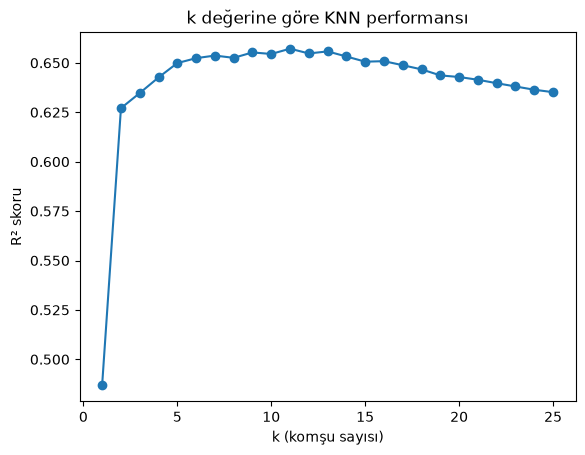

In [31]:
import matplotlib.pyplot as plt

k_degerleri = range(1, 26)
skorlar = []

for k in k_degerleri:
    model = KNeighborsRegressor(n_neighbors=k)
    skor = cross_val_score(model, X_rescaled, y, cv=5).mean()
    skorlar.append(skor)

plt.plot(k_degerleri, skorlar, marker="o")
plt.xlabel("k (komşu sayısı)")
plt.ylabel("R² skoru")
plt.title("k değerine göre KNN performansı")
plt.show()

❓ K'nın hangi değeri en iyi performansı üretir? Cevabınızı `best_k` değişken adı altında kaydedin.

In [32]:
best_k = k_degerleri[skorlar.index(max(skorlar))]
best_k

11

<details>
<summary> 👉 Çözüm 👈</summary>
    
Grafiğinize bakarak, skorun k = 5 civarında artmayı durdurduğunu ve maksimum skorun k = 11 için ulaşıldığını görmelisiniz.

</details>

❓ $k$ < 5 değerleri için modelin kötü performansını nasıl yorumluyorsunuz?

<details>
<summary> 👉 Çözüm 👈</summary>
    
K çok küçük olduğunda, model eğitim kümesine aşırı uyum gösterme eğiliminde olacaktır. İyi genelleştirebilmek için çok az noktaya odaklanacaktır. K'yı artırmak modele tahminlerini dayandıracağı daha fazla örnek verecektir.

</details>

### 🧪 Kodunuzu kontrol edin

In [33]:
from nbresult import ChallengeResult

result = ChallengeResult('optimal_k',
                         optimal_k = best_k)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.14.4, pytest-9.1.1, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /home/ceren/workintech/data-orders-regression/S16D1-S-data-knn/tests
plugins: platformdirs-4.12.2, anyio-4.15.1, dash-4.4.1, typeguard-4.4.4
collecting ... collected 1 item

test_optimal_k.py::TestOptimal_k::test_optimal_K_around_10 PASSED        [100%]

============================== 1 passed in 0.02s ===============================


💯 You can commit your code:

git add tests/optimal_k.pickle

git commit -m 'Completed optimal_k step'

git push origin master



# KNN'de Aşırı Uyum

💡 KNN'lerin K parametresi çok küçük olduğunda, eğitim kümesine aşırı uyum gösterme ve iyi genelleştirememe riski vardır. 

👇 K=2 parametreli bir KNN'in öğrenme eğrilerini çizin.

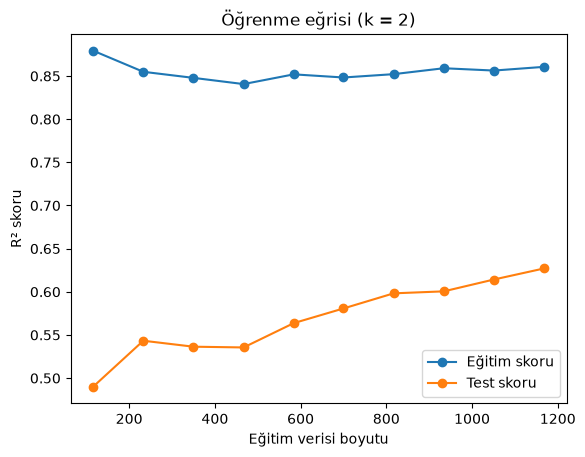

In [34]:
from sklearn.model_selection import learning_curve
import numpy as np

def ogrenme_egrisi_ciz(k):
    train_sizes, train_scores, test_scores = learning_curve(
        KNeighborsRegressor(n_neighbors=k),
        X_rescaled, y,
        train_sizes=np.linspace(0.1, 1.0, 10),
        cv=5
    )
    plt.plot(train_sizes, train_scores.mean(axis=1), marker="o", label="Eğitim skoru")
    plt.plot(train_sizes, test_scores.mean(axis=1), marker="o", label="Test skoru")
    plt.xlabel("Eğitim verisi boyutu")
    plt.ylabel("R² skoru")
    plt.title(f"Öğrenme eğrisi (k = {k})")
    plt.legend()
    plt.show()

ogrenme_egrisi_ciz(2)

👉 Yüksek eğitim skoru ama düşük test skoru gözlemlemelisiniz. ⚠️ Aşırı uyum uyarısı ⚠️ Bu çok düşük K parametresinden kaynaklanır.

# İdeal K

👇 Bu sefer, "$k$ Optimizasyonu" bölümünde bulduğunuz ideal K değeri için öğrenme eğrilerini çizin.

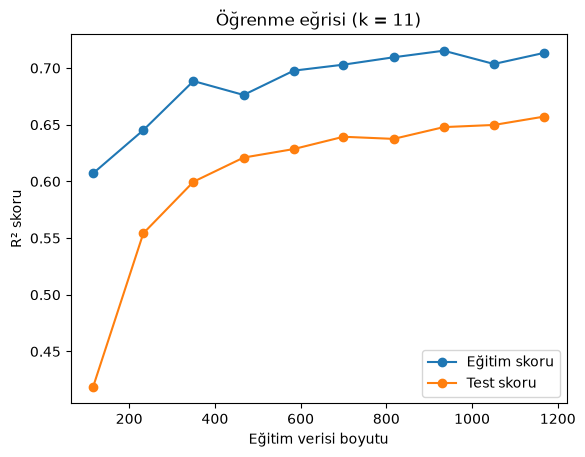

In [35]:
ogrenme_egrisi_ciz(best_k)

👉 Eğriler yakınsamaya yakın olmalı, bu da modelin daha az aşırı uyum gösterdiğini ve daha iyi genelleştirdiğini gösterir.

💡 KNN modelleriyle modelleme yaparken hatırlanması gereken iki temel unsur vardır:  
    1. Mesafe tabanlı algoritmalar özelliklerin ölçeğine son derece duyarlıdır  
    2. K ayarlanmalıdır: performans, genelleştirme ve aşırı uyum arasındaki dengeyi kontrol eder

❓ Optimize edilmiş KNN modelinin gerçek fiyat ile tahmin edilen fiyat arasındaki ortalama fark nedir? Cevabınızı hesaplayın ve `price_error` değişken adı altında kaydedin

<details>
<summary> 💡 İpucu </summary>
    
Hesaplamanız gereken metrik **Negatif Ortalama Mutlak Hata (MAE)**'dır.

</details>

In [36]:
price_error = -cross_val_score(
    KNeighborsRegressor(n_neighbors=best_k),
    X_rescaled, y,
    cv=5,
    scoring="neg_mean_absolute_error"
).mean()
price_error

np.float64(30823.53430884184)

### 🧪 Kodunuzu kontrol edin

In [37]:
from sklearn.linear_model import LinearRegression

linreg_score = cross_val_score(LinearRegression(), X_rescaled, y, cv=5).mean()
best_knn = max(skorlar)

print("Linear Regression R²:", linreg_score)
print("En iyi KNN R²:", best_knn)

Linear Regression R²: 0.5944790982110585
En iyi KNN R²: 0.6571704043326225


# Model Seçimi

❓ Ev fiyatlarını tahmin etme görevini gerçekleştirmek için bu iki modelden hangisini seçersiniz:
- Az önce ayarladığınız KNN modeli
- Bir Linear Regression modeli

Cevabınızı "KNN" veya "LinearReg" olarak `best_model` değişken adı altında string olarak kaydedin.

<details>
<summary> 💡 İpucu </summary>
    
Hangisini seçeceğinize karar vermek için, aynı görev üzerinde bir Linear Regression skorunu değerlendirmeniz ve KNN'in skoruyla karşılaştırmanız gerekecek. Aynı metrikleri karşılaştırdığınızdan emin olun!!

</details>

In [1]:
best_model = "KNN"

💡 Her iki modelin metriklerini karşılaştırdığınızda, KNN modeli Linear Regression'ı geçmelidir. Bu, verideki doğrusal olmayan kalıpları yakalama yeteneğinden kaynaklanabilir.

### 🧪 Kodunuzu kontrol edin

In [39]:
from nbresult import ChallengeResult

result = ChallengeResult('best_model',
                         model = best_model)
result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.14.4, pytest-9.1.1, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /home/ceren/workintech/data-orders-regression/S16D1-S-data-knn/tests
plugins: platformdirs-4.12.2, anyio-4.15.1, dash-4.4.1, typeguard-4.4.4
collecting ... collected 1 item

test_best_model.py::TestBest_model::test_best_model FAILED               [100%]

=================================== FAILURES ===================================
________________________ TestBest_model.test_best_model ________________________

self = <tests.test_best_model.TestBest_model testMethod=test_best_model>

    def test_best_model(self):
>       self.assertEqual(self.result.model, "KNN")
E       AssertionError: 'LinearReg' != 'KNN'
E       - LinearReg
E       + KNN

test_best_model.py:6: AssertionError
=========================== short test summary info ============================
FAILED test_best_model.py::TestBe

# 🏁